In [1]:
import numpy as np
import matplotlib.pyplot as plt

from rowland_geometry.dispersive import DispersiveRefocusing

In [34]:
drr = DispersiveRefocusing(
    diameter= 500,
    bragg = 80,
    displacement = 25,
    optic_diameter= 300,
    asymmetry= 10,
)



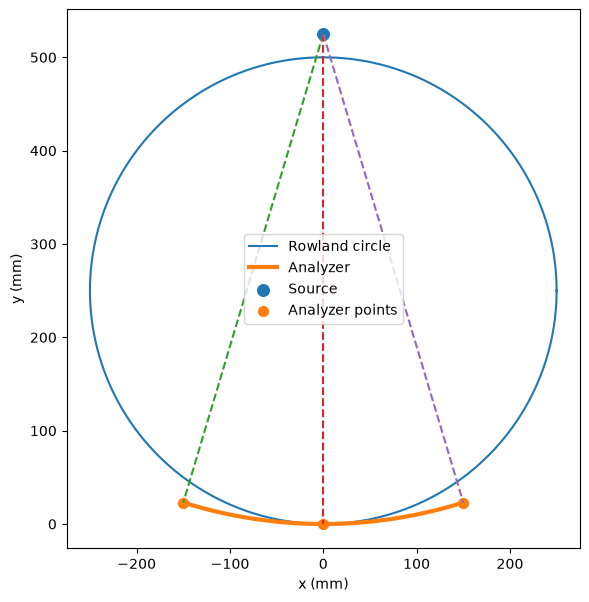

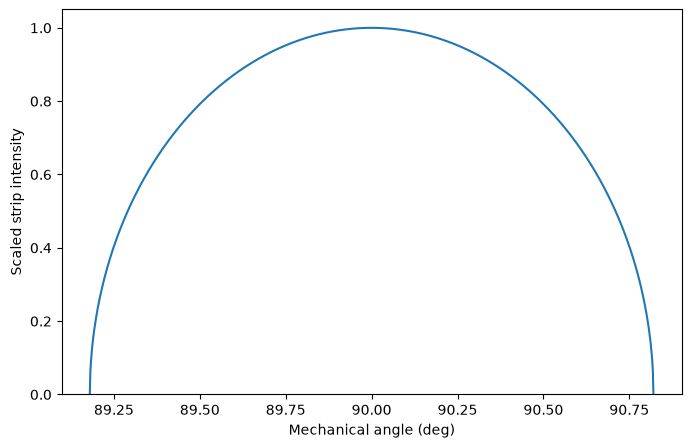

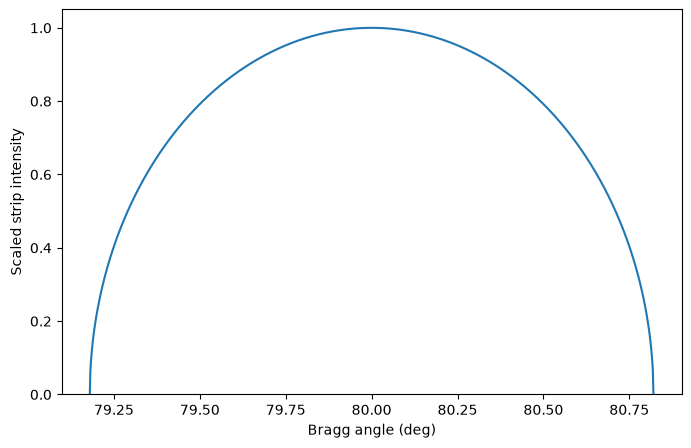

In [35]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Geometry pieces
# ------------------------------------------------------------

circle = drr.on_circle_geometry

source = drr.pos_source
profile = drr.profile_analyzer_pos

left = profile[0]
center = profile[len(profile) // 2]
right = profile[-1]

# Rowland circle
theta = np.linspace(0, 2 * np.pi, 1000)

R_circle = drr.diameter / 2.0
xc = 0.0
yc = R_circle

x_circle = xc + R_circle * np.cos(theta)
y_circle = yc + R_circle * np.sin(theta)

# ------------------------------------------------------------
# Plot 1: geometry + three rays
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 7))

ax.plot(x_circle, y_circle, label="Rowland circle")

ax.plot(
    profile[:, 0],
    profile[:, 1],
    linewidth=3,
    label="Analyzer",
)

ax.scatter(
    source[0],
    source[1],
    s=70,
    label="Source",
)

ax.scatter(
    [left[0], center[0], right[0]],
    [left[1], center[1], right[1]],
    s=50,
    label="Analyzer points",
)

for point in [left, center, right]:
    ax.plot(
        [source[0], point[0]],
        [source[1], point[1]],
        linestyle="--",
    )

ax.set_aspect("equal")
ax.set_xlabel("x (mm)")
ax.set_ylabel("y (mm)")
ax.legend()

plt.show()


# ------------------------------------------------------------
# Normalize strip weights
# ------------------------------------------------------------

weight = drr.profile_analyzer_weight
weight_scaled = weight / np.max(weight)


# ------------------------------------------------------------
# Plot 2: mechanical angle vs strip intensity
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    drr.profile_analyzer_mech,
    weight_scaled,
)

ax.set_xlabel("Mechanical angle (deg)")
ax.set_ylabel("Scaled strip intensity")
ax.set_ylim(0, 1.05)

plt.show()


# ------------------------------------------------------------
# Plot 3: Bragg angle vs strip intensity
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    drr.profile_analyzer_bragg,
    weight_scaled,
)

ax.set_xlabel("Bragg angle (deg)")
ax.set_ylabel("Scaled strip intensity")
ax.set_ylim(0, 1.05)

plt.show()